问题1

In [1]:
import pandas as pd
import seaborn as sns
import numpy as np
import matplotlib.pyplot as plt
import warnings as w
w.filterwarnings('ignore')

plt.rcParams['font.sans-serif'] = ['SimHei']  # 使用黑体，字体设置
plt.rcParams['axes.unicode_minus'] = False  # 正确显示负号

In [2]:
#读文件
songs=pd.read_csv('数据1_songs.csv',names=['song_id', 'artist_id', 'publish_time', 'song_init_plays', 'Language', 'Gender'])
songs.head()

,song_id,artist_id,publish_time,song_init_plays,Language,Gender
0,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1
1,c0d7130777c1f1c417e78646946ed909,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1
2,200c9131cf929bab418d380356be5f42,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1
3,78fedfdf13fc820e363e39986ff91e94,03c6699ea836decbc5c8fc2dbae7bd3b,20110910,1717,1,1
4,95b99faf432d33772d63f828bf2d0921,03c6699ea836decbc5c8fc2dbae7bd3b,20110910,434,1,1


In [3]:
#读文件
user_actions=pd.read_csv('数据2_user_actions.csv',names=['user_id', 'song_id', 'gmt_create', 'action_type', 'Ds'])
user_actions.head()

,user_id,song_id,gmt_create,action_type,Ds
0,7063b3d0c075a4d276c5f06f4327cf4a,effb071415be51f11e845884e67c0f8c,1426406400,1,20150315
1,0db66c0dd3993fd3504bb98c3beb15b3,f87ff481d85d2f95335ab602f38a7655,1426417200,1,20150315
2,f8c065dc140ec74c6e44144164e618e3,8a27d9a6c59628c991c154e8d93f412e,1426406400,2,20150315
3,2c6082cf0d68e244f2a10325e8d1b85b,ecea5fe33e6817d09c395f2910479728,1426417200,1,20150315
4,2c6082cf0d68e244f2a10325e8d1b85b,31a3d0420d89c9b121bb55dbdbbeda6b,1426417200,1,20150315


In [4]:
#查看数据
songs.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 26958 entries, 0 to 26957
Data columns (total 6 columns):
 #   Column           Non-Null Count  Dtype 
---  ------           --------------  ----- 
 0   song_id          26958 non-null  object
 1   artist_id        26958 non-null  object
 2   publish_time     26958 non-null  int64 
 3   song_init_plays  26958 non-null  int64 
 4   Language         26958 non-null  int64 
 5   Gender           26958 non-null  int64 
dtypes: int64(4), object(2)
memory usage: 1.2+ MB


In [5]:
#查看数据
user_actions.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15884087 entries, 0 to 15884086
Data columns (total 5 columns):
 #   Column       Dtype 
---  ------       ----- 
 0   user_id      object
 1   song_id      object
 2   gmt_create   int64 
 3   action_type  int64 
 4   Ds           int64 
dtypes: int64(3), object(2)
memory usage: 605.9+ MB


In [6]:
#清洗数据
user_actions.isnull().sum()

user_id        0
song_id        0
gmt_create     0
action_type    0
Ds             0
dtype: int64

In [7]:
#合并数据集
df=pd.merge(songs,user_actions,on='song_id',how='left')
df.head()

,song_id,artist_id,publish_time,song_init_plays,Language,Gender,user_id,gmt_create,action_type,Ds
0,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,3f720d38240f8fb0a994c3af0108f664,1.440166e+09,1.0,20150821.0
1,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,1846d972f4bea247c5a04cf0a0f1915e,1.440162e+09,1.0,20150821.0
2,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,2b372da453f096a433c1c2edea7a17f4,1.440133e+09,1.0,20150821.0
3,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,fe5b1c3da3b029590b064d9274cf5b1f,1.440148e+09,1.0,20150821.0
4,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,a99fb4fa365f1097de7511e9be227b8b,1.440652e+09,1.0,20150827.0


In [8]:
#查看数据
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 15886102 entries, 0 to 15886101
Data columns (total 10 columns):
 #   Column           Dtype  
---  ------           -----  
 0   song_id          object 
 1   artist_id        object 
 2   publish_time     int64  
 3   song_init_plays  int64  
 4   Language         int64  
 5   Gender           int64  
 6   user_id          object 
 7   gmt_create       float64
 8   action_type      float64
 9   Ds               float64
dtypes: float64(3), int64(4), object(3)
memory usage: 1.2+ GB


In [9]:
#查看数据缺失值
df.isnull().sum()

song_id               0
artist_id             0
publish_time          0
song_init_plays       0
Language              0
Gender                0
user_id            2015
gmt_create         2015
action_type        2015
Ds                 2015
dtype: int64

In [10]:
#清洗数据
df=df.dropna()

In [11]:
#时间转换
df["play_time"] = pd.to_datetime(df["gmt_create"], unit="s")
df["publish_date"] = pd.to_datetime(df["publish_time"].astype(str), format="%Y%m%d")
df["ds"] = pd.to_datetime(df["Ds"].astype(int).astype(str), format="%Y%m%d")
df['current_date'] = pd.to_datetime('2015-08-31')
df['days_since_publish'] = (df['current_date'] - df['publish_date']).dt.days  # 发行天数



In [12]:
# 筛选出发行时间晚于记录时间的异常数据
mask = df['publish_date'] > df['ds']
print(f"原始数据量：{len(df)} 条")
print(f"异常数据量：{mask.sum()} 条")

# 删除异常数据
df = df[~mask].copy()  # ~mask 表示取反（保留正常数据）
print(f"删除后数据量：{len(df)} 条")

# 验证删除后时间逻辑是否合规
if (df['publish_date'] > df['ds']).any():
    print("警告：仍存在时间逻辑矛盾的数据！")
else:
    print("时间逻辑验证通过：所有发行时间均早于或等于记录时间")

原始数据量：15884087 条
异常数据量：391724 条
删除后数据量：15492363 条
时间逻辑验证通过：所有发行时间均早于或等于记录时间


In [13]:
max_publish_date = df['publish_date'].max()
print(f"最晚发行日期：{max_publish_date}")

最晚发行日期：2015-08-25 00:00:00


In [14]:
max_ds_date = df['ds'].max()
print(f"最晚记录日期：{max_ds_date}")

最晚记录日期：2015-08-30 00:00:00


In [15]:
min_publish_date = df['publish_date'].min()
print(f"最早发行日期：{min_publish_date}")

最早发行日期：1960-07-28 00:00:00


In [16]:
min_ds_date = df['ds'].min()
print(f"最早记录日期：{min_ds_date}")

最早记录日期：2015-03-01 00:00:00


In [17]:
df['ds'].value_counts()

ds
2015-05-21    107537
2015-05-20    107104
2015-08-21    102045
2015-05-22     99848
2015-08-20     99190
               ...  
2015-03-06     64691
2015-03-07     64154
2015-03-01     60385
2015-03-03     59273
2015-03-02     56391
Name: count, Length: 183, dtype: int64

In [18]:
#分为三种行为类型
df["is_play"] = (df["action_type"] == 1).astype(int)
df["is_download"] = (df["action_type"] == 2).astype(int)
df["is_collect"] = (df["action_type"] == 3).astype(int)
df.head()

,song_id,artist_id,publish_time,song_init_plays,Language,Gender,user_id,gmt_create,action_type,Ds,play_time,publish_date,ds,current_date,days_since_publish,is_play,is_download,is_collect
0,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,3f720d38240f8fb0a994c3af0108f664,1.440166e+09,1.0,20150821.0,2015-08-21 14:00:00,2015-03-25,2015-08-21,2015-08-31,159,1,0,0
1,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,1846d972f4bea247c5a04cf0a0f1915e,1.440162e+09,1.0,20150821.0,2015-08-21 13:00:00,2015-03-25,2015-08-21,2015-08-31,159,1,0,0
2,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,2b372da453f096a433c1c2edea7a17f4,1.440133e+09,1.0,20150821.0,2015-08-21 05:00:00,2015-03-25,2015-08-21,2015-08-31,159,1,0,0
3,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,fe5b1c3da3b029590b064d9274cf5b1f,1.440148e+09,1.0,20150821.0,2015-08-21 09:00:00,2015-03-25,2015-08-21,2015-08-31,159,1,0,0
4,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,a99fb4fa365f1097de7511e9be227b8b,1.440652e+09,1.0,20150827.0,2015-08-27 05:00:00,2015-03-25,2015-08-27,2015-08-31,159,1,0,0


In [19]:
# 聚合用户行为数据：按歌曲统计播放/收藏/下载次数
behavior_agg = df.groupby('song_id').agg({
    'is_play': lambda x: np.sum(x == 1),  # 播放次数（action_type=1）
    'user_id': 'nunique',                     # 唯一用户数（活跃度）
    'is_download': lambda x: np.sum(x == 1),      # 下载次数（此处临时用song_id计数，需根据实际字段调整）
    'is_collect': lambda x: np.sum(x == 1)    # 收藏次数（同上）
}).rename(columns={
    'is_play': 'play_count',
    'user_id': 'unique_user_count',
    'is_download': 'download_count',
    'is_collect': 'collect_count'
}).reset_index()

# 合并回原数据（保留单条记录即可，因后续分析基于歌曲维度）
df = df.drop_duplicates(subset='song_id').merge(behavior_agg, on='song_id', how='left')

In [20]:
artist_stats = df.groupby('artist_id')['play_count'].mean().reset_index()
artist_stats.columns = ['artist_id', 'artist_avg_play']

# 合并回主表
df = df.merge(artist_stats, on='artist_id', how='left')
df.isnull().sum()

song_id               0
artist_id             0
publish_time          0
song_init_plays       0
Language              0
Gender                0
user_id               0
gmt_create            0
action_type           0
Ds                    0
play_time             0
publish_date          0
ds                    0
current_date          0
days_since_publish    0
is_play               0
is_download           0
is_collect            0
play_count            0
unique_user_count     0
download_count        0
collect_count         0
artist_avg_play       0
dtype: int64

In [21]:
# 时间特征挖掘
df['publish_month'] = df['publish_date'].dt.month  # 发行月份
df['publish_quarter'] = df['publish_date'].dt.quarter  # 发行季度
df['publish_weekday'] = df['publish_date'].dt.weekday  # 发行周几
df['publish_hour'] = df['play_time'].dt.hour  # 行为发生小时


# 分类特征编码
df['Language'] = df['Language'].astype(str)
df['Gender'] = df['Gender'].astype(str)

# 对分类特征进行目标编码（考虑到高基数的artist_id）
for col in ['Language', 'Gender', 'artist_id']:
    target_mean = df.groupby(col)['play_count'].mean()
    df[f'{col}_encoded'] = df[col].map(target_mean)


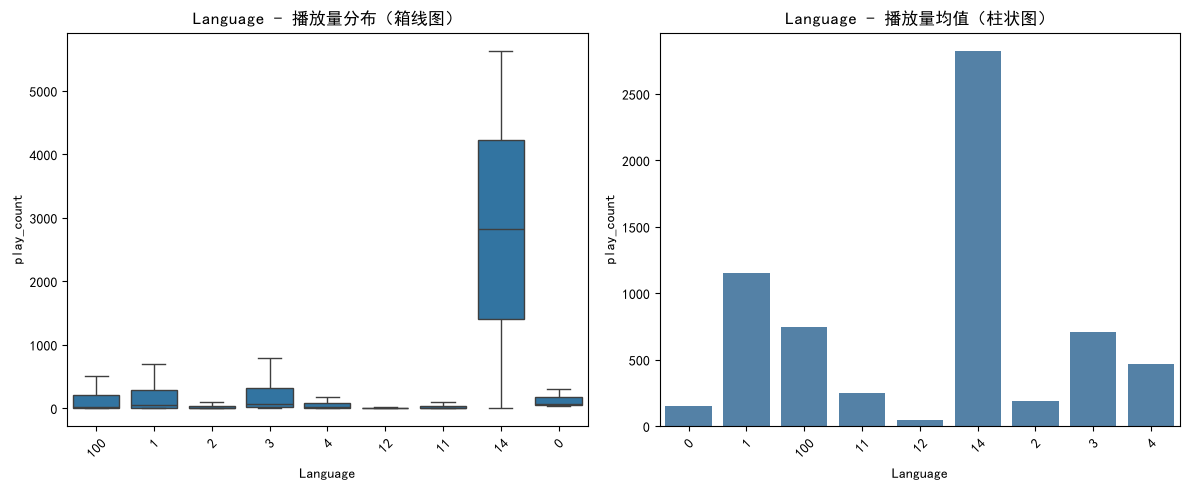

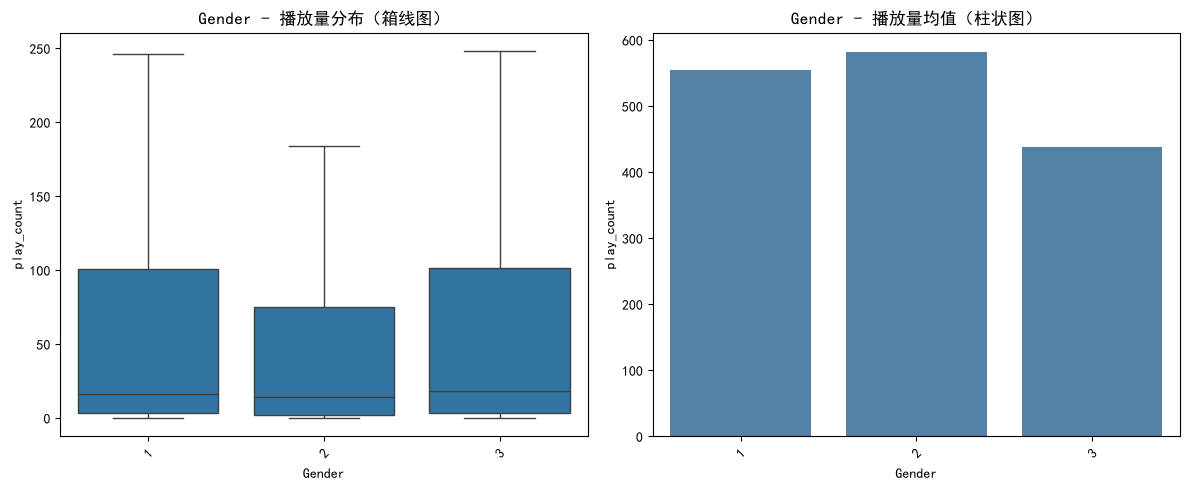

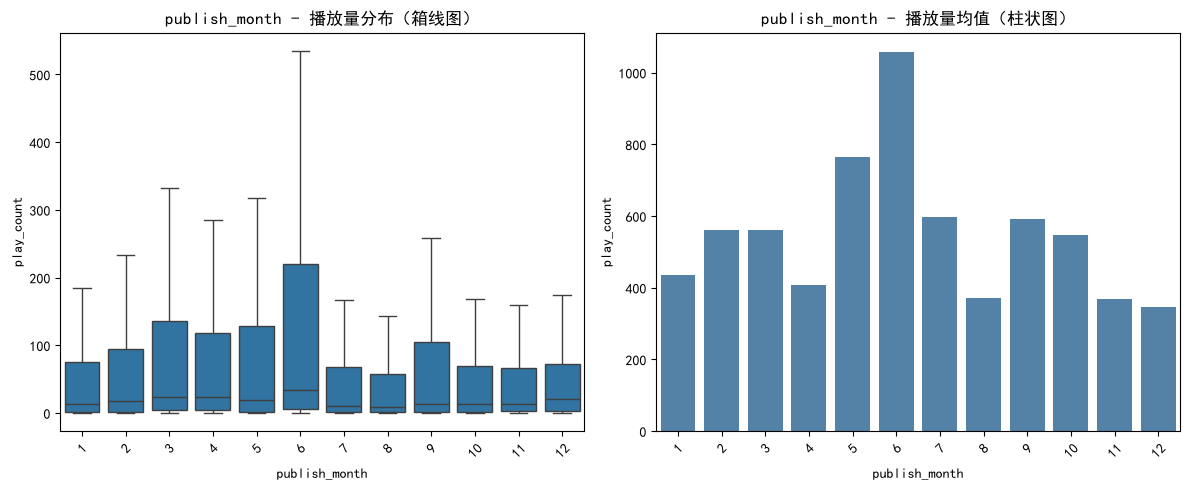

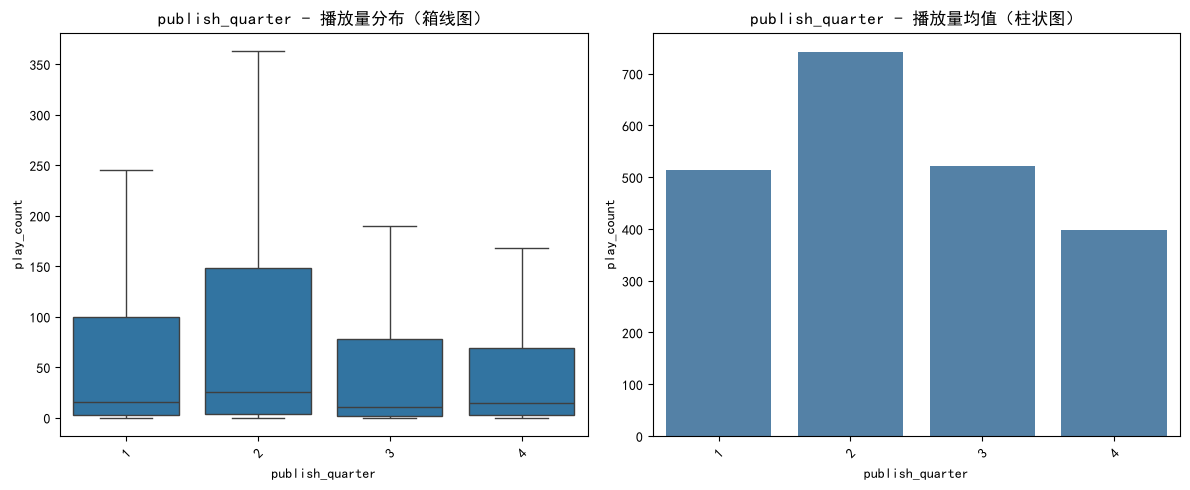

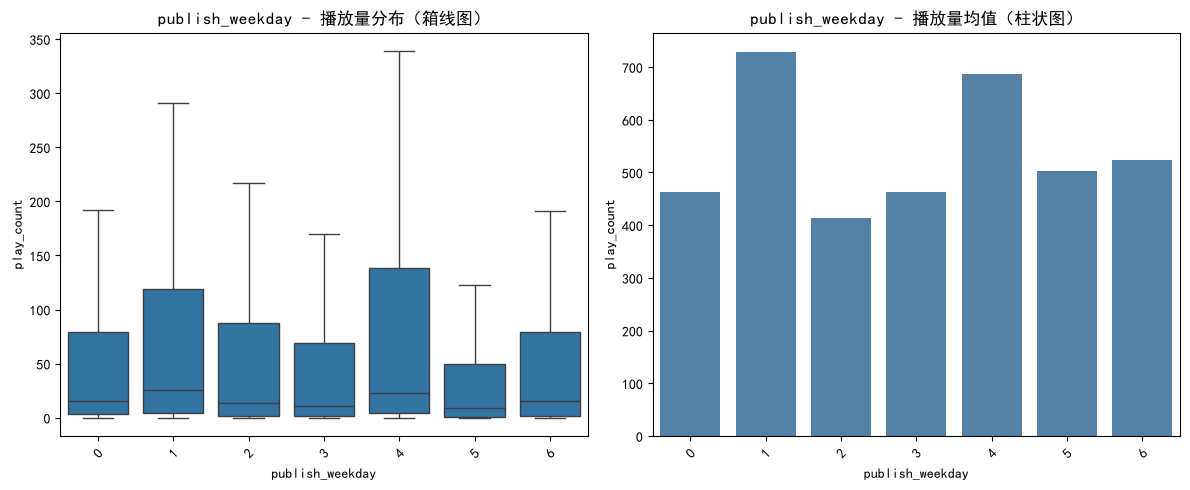

In [22]:
cat_features = ['Language', 'Gender', 'publish_month', 'publish_quarter', 'publish_weekday']

# 遍历每个分类特征，绘制箱线图和均值对比图
for col in cat_features:
    plt.figure(figsize=(12, 5))
    
    # 箱线图（展示播放量分布）
    plt.subplot(1, 2, 1)
    sns.boxplot(x=col, y='play_count', data=df, showfliers=False)  # showfliers=False 隐藏异常值
    plt.title(f'{col} - 播放量分布（箱线图）')
    plt.xticks(rotation=45)
    
    # 柱状图（展示播放量均值）
    plt.subplot(1, 2, 2)
    target_mean = df.groupby(col)['play_count'].mean().reset_index()
    sns.barplot(x=col, y='play_count', data=target_mean, color='steelblue')
    plt.title(f'{col} - 播放量均值（柱状图）')
    plt.xticks(rotation=45)
    
    plt.tight_layout()
    plt.show()

In [23]:
from scipy.stats import f_oneway

# 单因素方差分析（ANOVA）：检验分类特征对播放量的显著性影响
for col in cat_features:
    groups = [group['play_count'] for name, group in df.groupby(col)]
    f_stat, p_value = f_oneway(*groups)
    print(f'{col} 对播放量的 ANOVA 检验：p值 = {p_value:.4f}')

Language 对播放量的 ANOVA 检验：p值 = 0.0000
Gender 对播放量的 ANOVA 检验：p值 = 0.0795
publish_month 对播放量的 ANOVA 检验：p值 = 0.0000
publish_quarter 对播放量的 ANOVA 检验：p值 = 0.0002
publish_weekday 对播放量的 ANOVA 检验：p值 = 0.0030


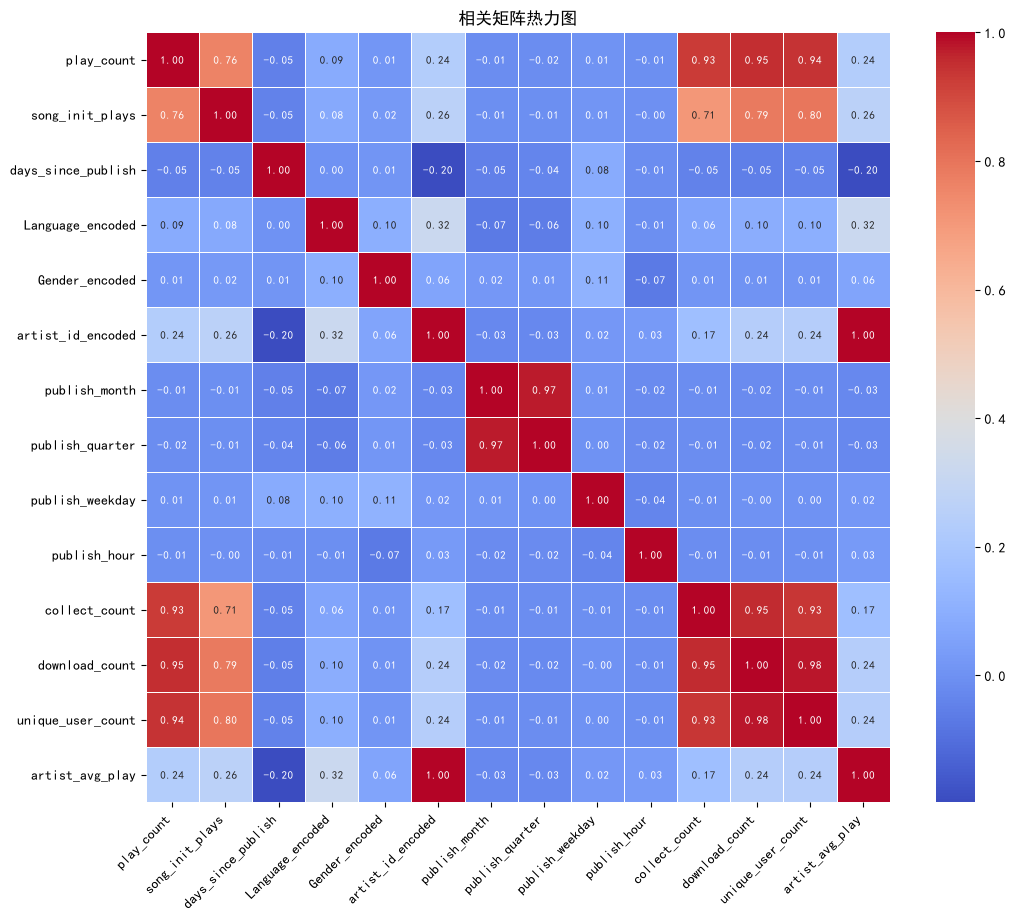

In [24]:
# 计算相关性矩阵，画热力图

selected_features = ['play_count',
    'song_init_plays', 'days_since_publish',
    'Language_encoded', 'Gender_encoded', 'artist_id_encoded',
    'publish_month', 'publish_quarter', 'publish_weekday', 'publish_hour',
     'collect_count', 'download_count', 'unique_user_count', 'artist_avg_play',
   
]
numeric_features = df[selected_features].select_dtypes(include=[np.number])


corr_matrix = numeric_features.corr()

plt.figure(figsize=(12, 10))  # 调整画布大小以适应标注
sns.heatmap(
    corr_matrix,          # 相关性矩阵
    annot=True,           # 显示数字标注
    cmap='coolwarm',      # 颜色映射（同之前）
    fmt='.2f',            # 标注格式（保留 2 位小数）
    xticklabels=corr_matrix.columns, 
    yticklabels=corr_matrix.columns, 
    linewidths=0.5,       # 格子线宽度（增强可读性）
    annot_kws={"size": 8}  # 标注字体大小（根据画布调整）
)
plt.title('相关矩阵热力图')
plt.xticks(rotation=45, ha='right')  # 旋转 x 轴标签，避免重叠
plt.show()

In [25]:
numeric_features = [
    'song_init_plays', 'days_since_publish', 'play_count', 
    'collect_count', 'download_count', 'unique_user_count',
    'artist_avg_play',
]
df1=df.copy()

In [26]:
from sklearn.preprocessing import StandardScaler, MinMaxScaler

# 标准化处理
scaler = StandardScaler()
df1[numeric_features] = scaler.fit_transform(df1[numeric_features])


In [27]:
df1['ds']

0       2015-08-21
1       2015-08-21
2       2015-08-21
3       2015-08-21
4       2015-08-26
           ...    
24909   2015-03-15
24910   2015-05-08
24911   2015-03-19
24912   2015-04-16
24913   2015-04-30
Name: ds, Length: 24914, dtype: datetime64[ns]

In [28]:
# 定义时间区间
train_start = pd.Timestamp('2015-03-01')
train_end = pd.Timestamp('2015-08-15')
test_start = pd.Timestamp('2015-08-16')
test_end = pd.Timestamp('2015-08-30')

# 筛选数据
train_data = df1[(df1['ds'] >= train_start) & (df1['ds'] <= train_end)]
test_data = df1[(df1['ds'] >= test_start) & (df1['ds'] <= test_end)]


In [29]:
# 构建模型数据集
selected_features = [
    'song_init_plays', 'days_since_publish',
    'Language_encoded', 'Gender_encoded', 'artist_id_encoded',
    'publish_month', 'publish_quarter', 'publish_weekday', 'publish_hour',
     'collect_count', 'download_count', 'unique_user_count', 'artist_avg_play',
   
]

In [30]:
from sklearn.model_selection import train_test_split

In [31]:
X_train = train_data[selected_features]
y_train = train_data['play_count']  # 目标变量：播放量
X_test = test_data[selected_features]
y_test = test_data['play_count']

In [32]:

#X = df1[selected_features]
#y = df1['play_count']

# 划分训练集和测试集
#X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

In [33]:
#训练集和测试集数据的形状
print(f"x_train shape: {X_train.shape}")
print(f"y_train shape: {y_train.shape}")
print(f"x_test shape: {X_test.shape}")
print(f"y_test shape: {y_test.shape}")

x_train shape: (15882, 13)
y_train shape: (15882,)
x_test shape: (9032, 13)
y_test shape: (9032,)


In [34]:
from sklearn.ensemble import RandomForestRegressor
#随机森林模型
model = RandomForestRegressor(n_estimators=60,max_depth=8, random_state=42)
# 训练模型
model.fit(X_train, y_train)
y_pred = model.predict(X_test)


In [35]:
# 评估模型
train_score = model.score(X_train, y_train)
test_score = model.score(X_test, y_test)
print(f"训练集R²: {train_score:.4f}")
print(f"测试集R²: {test_score:.4f}")

训练集R²: 0.9862
测试集R²: 0.6188


In [36]:
from sklearn.metrics import mean_squared_error, mean_absolute_error

# 计算RMSE（均方根误差）
rmse = np.sqrt(mean_squared_error(y_test, y_pred))

# 计算MAE（平均绝对误差）
mae = mean_absolute_error(y_test, y_pred)


print(f"测试集评估指标：")
print(f"RMSE: {rmse:.4f}")
print(f"MAE: {mae:.4f}")

测试集评估指标：
RMSE: 0.4435
MAE: 0.0174


               Feature  Importance
11   unique_user_count    0.456382
10      download_count    0.453370
0      song_init_plays    0.052231
9        collect_count    0.016183
1   days_since_publish    0.004378
12     artist_avg_play    0.003922
4    artist_id_encoded    0.003598
8         publish_hour    0.002776
7      publish_weekday    0.002042
2     Language_encoded    0.001974
5        publish_month    0.001788
6      publish_quarter    0.000699
3       Gender_encoded    0.000658


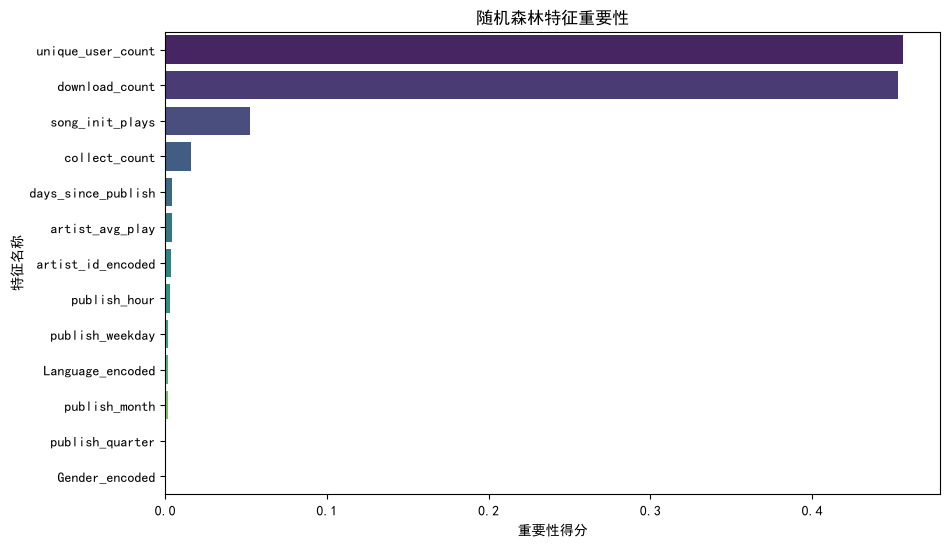

In [37]:
# 特征重要性分析
feature_importance = pd.DataFrame({
    'Feature': selected_features,
    'Importance': model.feature_importances_
}).sort_values('Importance', ascending=False)

print(feature_importance)
# 可视化特征重要性
plt.figure(figsize=(10, 6))
sns.barplot(x='Importance', y='Feature', data=feature_importance, palette='viridis')
plt.title('随机森林特征重要性')
plt.xlabel('重要性得分')
plt.ylabel('特征名称')
plt.show()



In [38]:
df['collect_count'].value_counts()

collect_count
0      16378
1       3249
2       1330
3        713
4        464
       ...  
195        1
172        1
598        1
312        1
227        1
Name: count, Length: 291, dtype: int64

问题2

In [39]:
df.head()

,song_id,artist_id,publish_time,song_init_plays,Language,Gender,user_id,gmt_create,action_type,Ds,...,download_count,collect_count,artist_avg_play,publish_month,publish_quarter,publish_weekday,publish_hour,Language_encoded,Gender_encoded,artist_id_encoded
0,c81f89cf7edd24930641afa2e411b09c,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,3f720d38240f8fb0a994c3af0108f664,1.440166e+09,1.0,20150821.0,...,509,2,2279.059406,3,1,2,14,746.000000,553.590497,2279.059406
1,c0d7130777c1f1c417e78646946ed909,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,1846d972f4bea247c5a04cf0a0f1915e,1.440101e+09,1.0,20150821.0,...,531,0,2279.059406,3,1,2,20,746.000000,553.590497,2279.059406
2,200c9131cf929bab418d380356be5f42,03c6699ea836decbc5c8fc2dbae7bd3b,20150325,0,100,1,1846d972f4bea247c5a04cf0a0f1915e,1.440101e+09,1.0,20150821.0,...,818,10,2279.059406,3,1,2,20,746.000000,553.590497,2279.059406
3,78fedfdf13fc820e363e39986ff91e94,03c6699ea836decbc5c8fc2dbae7bd3b,20110910,1717,1,1,4fe633f23fc6f6b7bfb97d3ca30624e2,1.440119e+09,1.0,20150821.0,...,23,1,2279.059406,9,3,5,1,1149.643202,553.590497,2279.059406
4,95b99faf432d33772d63f828bf2d0921,03c6699ea836decbc5c8fc2dbae7bd3b,20110910,434,1,1,6de2942aaacc6273f4079dbe106cff10,1.440565e+09,1.0,20150826.0,...,19,0,2279.059406,9,3,5,5,1149.643202,553.590497,2279.059406


In [40]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 24914 entries, 0 to 24913
Data columns (total 30 columns):
 #   Column              Non-Null Count  Dtype         
---  ------              --------------  -----         
 0   song_id             24914 non-null  object        
 1   artist_id           24914 non-null  object        
 2   publish_time        24914 non-null  int64         
 3   song_init_plays     24914 non-null  int64         
 4   Language            24914 non-null  object        
 5   Gender              24914 non-null  object        
 6   user_id             24914 non-null  object        
 7   gmt_create          24914 non-null  float64       
 8   action_type         24914 non-null  float64       
 9   Ds                  24914 non-null  float64       
 10  play_time           24914 non-null  datetime64[ns]
 11  publish_date        24914 non-null  datetime64[ns]
 12  ds                  24914 non-null  datetime64[ns]
 13  current_date        24914 non-null  datetime64

In [41]:
import pulp

In [42]:
train_data = df  # 训练集特征
test_data = df  # 候选歌曲池
from sklearn.ensemble import RandomForestRegressor
# 训练预测模型
model = RandomForestRegressor(n_estimators=100, random_state=42)
model.fit(train_data[["download_count", "unique_user_count", "song_init_plays", "collect_count"]], train_data["play_count"])

# 预测候选歌曲播放量
df["predicted_plays"] = model.predict(test_data[["download_count", "unique_user_count", "song_init_plays", "collect_count"]])

In [43]:
# 按艺人聚合关键指标（性别、总预测播放量、语言分布）
artist_features = df.groupby('artist_id').agg({
    'Gender': 'first',
    'predicted_plays': 'sum',
    'Language': lambda x: (x == '1').sum(),  # 中文歌曲数量（Language=1）
    'song_id': 'count'  # 艺人总歌曲数
}).rename(columns={
    'Gender': 'gender',
    'predicted_plays': 'total_predicted_plays',
    'Language': 'chinese_song_count',
    'song_id': 'song_count'
}).reset_index()

In [44]:
# 筛选有效艺人：性别为男（1）或女（2），且至少有1首歌曲
valid_artists = artist_features[
    artist_features['gender'].isin(['1', '2']) & (artist_features['song_count'] >= 1)
].reset_index(drop=True)

In [45]:
# 获取每个艺人的Top3热门歌曲（按预测播放量排序）
top3_songs = df.groupby('artist_id').apply(
    lambda group: group.sort_values('predicted_plays', ascending=False).head(3)
).reset_index(drop=True)
top3_songs['rank'] = top3_songs.groupby('artist_id').cumcount() + 1  # 标记歌曲排名（1-3）

In [46]:
#线性规划模型
#创建优化模型（最大化总预测播放量）
lp_model = pulp.LpProblem("Artist_Recommendation_Optimization", pulp.LpMaximize)

In [47]:
# 是否选择该艺人（Binary变量）
artist_ids = valid_artists['artist_id'].unique()
x = lp_model.add_variable_dicts(
    "select_artist",
    artist_ids,
    cat=pulp.LpBinary
)


In [48]:
# 该艺人推荐的歌曲数量（整数变量，1-3首）
s = lp_model.add_variable_dicts(
    "songs_per_artist",
    artist_ids,
    lowBound=0,
    upBound=3,
    cat=pulp.LpInteger
)


In [49]:
# 歌曲级决策变量（Binary，用于语言约束计算）
song_vars = {}
for idx, row in top3_songs.iterrows():
    aid = row['artist_id']
    rank = row['rank']
    song_vars[(aid, rank)] = lp_model.add_variable(
        f"song_{aid}_{rank}",
        cat=pulp.LpBinary
    )


In [50]:
# 目标函数
# 关联歌曲预测值与决策变量（通过歌曲排名获取对应播放量）
lp_model += pulp.lpSum(
    row['predicted_plays'] * song_vars[(row['artist_id'], row['rank'])]
    for _, row in top3_songs.iterrows()
), "Total_Predicted_Plays"

In [51]:
# 1. 总推荐位不超过50个（歌曲数量）
# 定义总推荐位约束（仅一次，名称唯一）
lp_model += pulp.lpSum(s[aid] for aid in artist_ids) <= 50, "Total_Slots_Constraint_1"  # 简化名称，确保唯一
# 2. 男/女艺人数量比例约束（1:1 ≤ M:F ≤ 2:1）
male_artists = valid_artists[valid_artists['gender'] == '1']['artist_id'].tolist()
female_artists = valid_artists[valid_artists['gender'] == '2']['artist_id'].tolist()

M = pulp.lpSum(x[aid] for aid in male_artists)
F = pulp.lpSum(x[aid] for aid in female_artists)

lp_model += M >= F, "Male_Female_Ratio_1_1"  # 唯一名称，如"比例1:1下限"
lp_model += M <= 2 * F, "Male_Female_Ratio_2_1"  # 唯一名称，如"比例2:1上限"

# 3. 艺人与歌曲数量关联约束（选艺人则至少推荐1首，推荐歌曲则必须选艺人）
for idx, aid in enumerate(artist_ids):
    # 约束1：推荐歌曲数等于实际选中的歌曲数（通过song_vars求和）
    lp_model += s[aid] == pulp.lpSum(song_vars[(aid, rank)] for rank in [1, 2, 3]), f"Song_Count_Constraint_{aid}"
    
    # 约束2：推荐歌曲数不超过3首，且与是否选择艺人关联（若选艺人，最多推荐3首）
    lp_model += s[aid] <= 3 * x[aid], f"Max_Songs_Per_Artist_{aid}"
    
    # 约束3：若选择艺人，至少推荐1首歌曲（若s[aid]≥1，则x[aid]=1）
    lp_model += s[aid] >= x[aid], f"Min_Songs_Per_Artist_{aid}"

# 4. 语言约束（中文≥40%总推荐位，外语≤50%）
# 计算推荐歌曲中的中文和外语数量
chinese_songs = pulp.lpSum(
    song_vars[(aid, rank)] for aid, rank in song_vars.keys()
    if top3_songs.loc[(top3_songs['artist_id'] == aid) & (top3_songs['rank'] == rank), 'Language'].values[0] == '1'
)

foreign_songs = pulp.lpSum(
    song_vars[(aid, rank)] for aid, rank in song_vars.keys()
    if top3_songs.loc[(top3_songs['artist_id'] == aid) & (top3_songs['rank'] == rank), 'Language'].astype(int).values[0] >= 2
)

total_slots = pulp.lpSum(s[aid] for aid in artist_ids)

lp_model += chinese_songs >= 0.4 * total_slots, "Chinese_Songs_Lower"
lp_model += foreign_songs <= 0.5 * total_slots, "Foreign_Songs_Upper"

In [52]:
# 求解模型
solve_stats = lp_model.solve()

# 检查求解状态
if pulp.LpSolveStatus(solve_stats.status).name != 'Optimal':
    print("警告：模型未找到最优解，可能存在约束冲突")

# 提取推荐结果
selected_artists = []
for aid in artist_ids:
    if x[aid].value() == 1:
        # 获取该艺人推荐的歌曲（非零的song_vars）
        recommended_songs = []
        for rank in [1, 2, 3]:
            sv = song_vars.get((aid, rank))
            if sv is not None and sv.value() == 1:
                song_data = top3_songs[
                    (top3_songs['artist_id'] == aid) & (top3_songs['rank'] == rank)
                ].iloc[0]
                recommended_songs.append({
                    'song_id': song_data['song_id'],
                    'language': '中文' if song_data['Language'] == '1' else '外语',
                    'predicted_plays': song_data['predicted_plays']
                })
        
        selected_artists.append({
            'artist_id': aid,
            'gender': '男' if valid_artists[valid_artists['artist_id'] == aid]['gender'].values[0] == '1' else '女',
            'recommended_songs': recommended_songs,
            'total_predicted': sum(song['predicted_plays'] for song in recommended_songs)
        })


In [53]:
# 验证约束条件
total_slots_used = sum(len(artist['recommended_songs']) for artist in selected_artists)
male_count = sum(1 for artist in selected_artists if artist['gender'] == '男')
female_count = sum(1 for artist in selected_artists if artist['gender'] == '女')
chinese_count = sum(1 for artist in selected_artists for song in artist['recommended_songs'] if song['language'] == '中文')
foreign_count = sum(1 for artist in selected_artists for song in artist['recommended_songs'] if song['language'] == '外语')

In [54]:
print("\n推荐结果摘要：")
print(f"总推荐位数量：{total_slots_used} / 50")
print(f"男艺人数量：{male_count}，女艺人数量：{female_count}，比例：{male_count}:{female_count}")
print(f"中文歌曲数量：{chinese_count} ({chinese_count/total_slots_used*100:.1f}%)")
print(f"外语歌曲数量：{foreign_count} ({foreign_count/total_slots_used*100:.1f}%)")
print(f"总预测播放量：{sum(artist['total_predicted'] for artist in selected_artists):.0f}")


推荐结果摘要：
总推荐位数量：50 / 50
男艺人数量：13，女艺人数量：13，比例：13:13
中文歌曲数量：39 (78.0%)
外语歌曲数量：11 (22.0%)
总预测播放量：2837920


In [55]:
# 输出详细推荐列表
print("\n详细推荐艺人及歌曲：")
for idx, artist in enumerate(selected_artists, 1):
    print(f"\n第{idx}位艺人：{artist['artist_id']} ({artist['gender']})")
    print(f"  总预测播放量：{artist['total_predicted']:.0f}")
    print("  推荐歌曲：")
    for song in artist['recommended_songs']:
        print(f"    - {song['song_id']}（{song['language']}）：{song['predicted_plays']:.0f}次")


详细推荐艺人及歌曲：

第1位艺人：03c6699ea836decbc5c8fc2dbae7bd3b (男)
  总预测播放量：17732
  推荐歌曲：
    - b6c00dc7ba77f1f789f53b7df09c3bdf（中文）：17732次

第2位艺人：099cd99056bf92e5f0e384465890a804 (女)
  总预测播放量：107440
  推荐歌曲：
    - 6a6544eb3eacc20a5c0cd4da5e4e4c7f（外语）：58905次
    - 4dcd9ea77e2d19657a2cfd9fd0ba113a（外语）：48536次

第3位艺人：14c4faf6682ac1bb86d346d9a2a1f8e3 (女)
  总预测播放量：65594
  推荐歌曲：
    - 33857e8523bd428f57b64b3501bcd027（中文）：32715次
    - 5a5c6f9101985f3612f3a4e7aea3faf7（中文）：17141次
    - c676f2aa6638d8554d3151d89d5059e4（中文）：15738次

第4位艺人：2e14d32266ee6b4678595f8f50c369ac (男)
  总预测播放量：78628
  推荐歌曲：
    - 5fc3eae9ac61fceef0b89d6a95e294f1（中文）：43959次
    - 241b146e6b7c30e64d02699f6f2f9ebe（中文）：34670次

第5位艺人：2ec1450a1389d4e3fc2a9a76c9378bb3 (女)
  总预测播放量：86048
  推荐歌曲：
    - 8a27d9a6c59628c991c154e8d93f412e（中文）：49826次
    - c2c03245b6f8460316fd252f1a2d9e4a（中文）：36222次

第6位艺人：2fe53ff8830b95d458af9ddd77fa5ffa (女)
  总预测播放量：62162
  推荐歌曲：
    - 6723ab4bd6269bfc6a51e899a9af77ff（中文）：62162次

第7位艺人：300dde62b988fc83eb6dba1b702e

In [56]:
solve_stats = lp_model.solve()
status_code = solve_stats.status
status_text = pulp.LpSolveStatus(status_code).name
print('求解状态：', status_text)


求解状态： Optimal


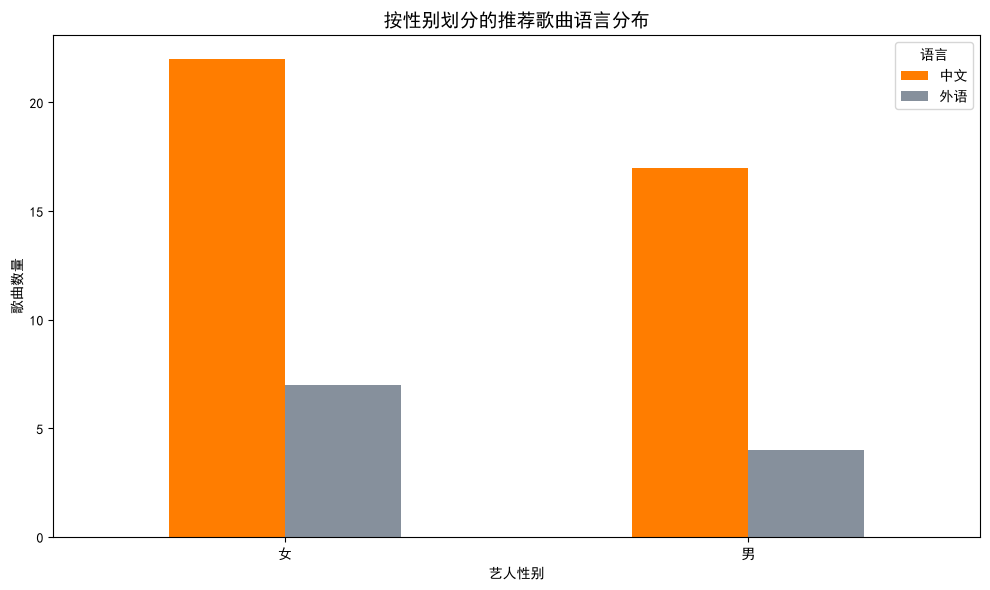

In [57]:
# 3. 性别与语言交叉分析
def visualize_gender_language(selected_artists):
    song_data = []
    for artist in selected_artists:
        for song in artist['recommended_songs']:
            song_data.append({
                '性别': artist['gender'],
                '语言': song['language']
            })
    song_df = pd.DataFrame(song_data)
    
    gender_language = song_df.groupby(['性别', '语言']).size().unstack(fill_value=0)
    
    plt.figure(figsize=(10, 6))
    gender_language.plot(kind='bar', ax=plt.gca(), color=['#FF7D00', '#86909C'])
    plt.title('按性别划分的推荐歌曲语言分布', fontsize=14)
    plt.xlabel('艺人性别')
    plt.ylabel('歌曲数量')
    plt.xticks(rotation=0)
    plt.legend(title='语言')
    plt.tight_layout()
    plt.show()
visualize_gender_language(selected_artists)

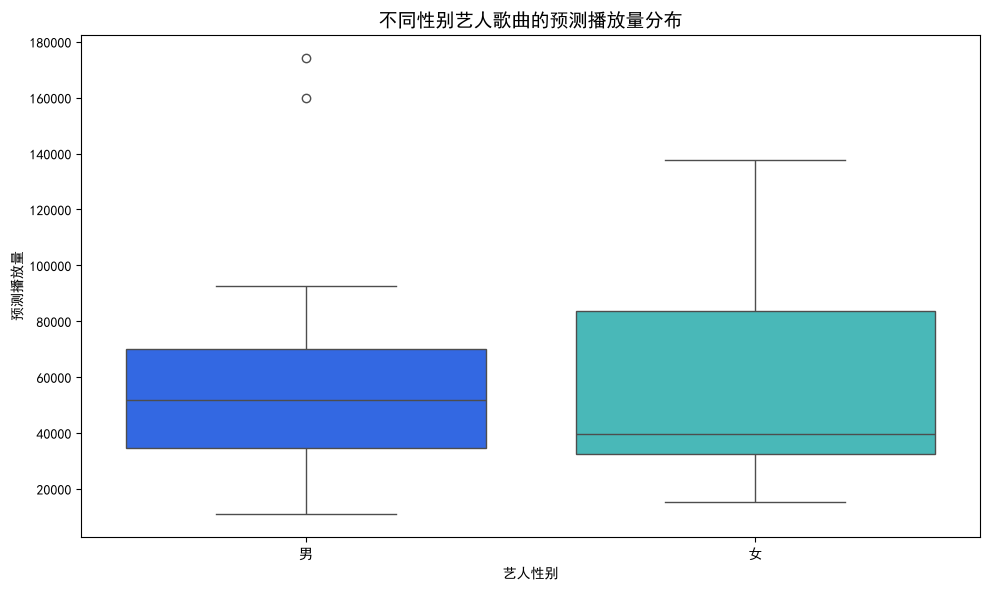

In [58]:
# 4. 预测播放量分布
def visualize_play_count_distribution(selected_artists):
    song_data = []
    for artist in selected_artists:
        for song in artist['recommended_songs']:
            song_data.append({
                '性别': artist['gender'],
                '预测播放量': song['predicted_plays']
            })
    song_df = pd.DataFrame(song_data)
    
    plt.figure(figsize=(10, 6))
    sns.boxplot(x='性别', y='预测播放量', data=song_df, palette=['#165DFF', '#36CBCB'])
    plt.title('不同性别艺人歌曲的预测播放量分布', fontsize=14)
    plt.xlabel('艺人性别')
    plt.ylabel('预测播放量')
    plt.tight_layout()
    plt.show()
visualize_play_count_distribution(selected_artists)

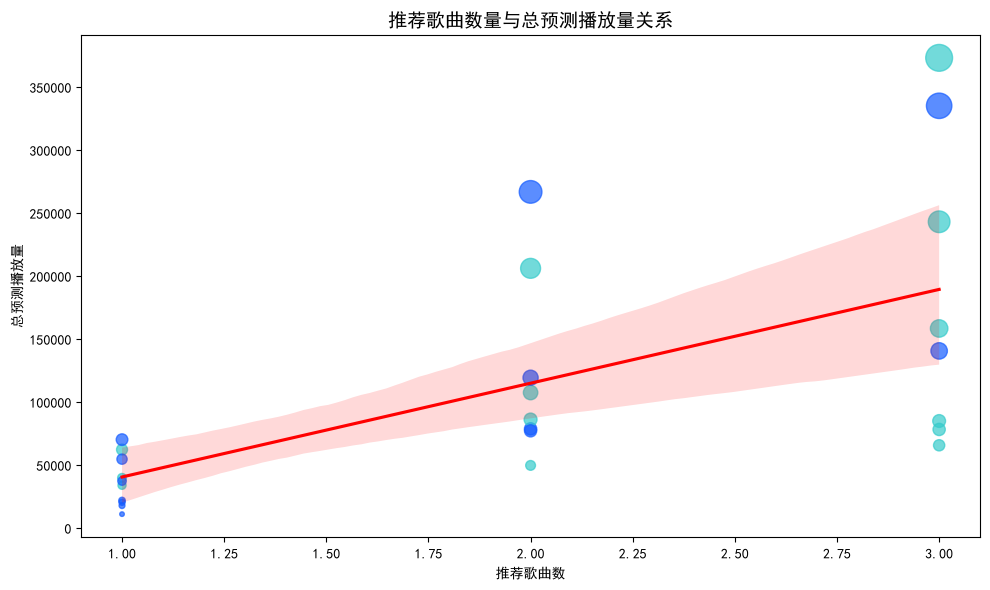

In [59]:
# 5. 推荐歌曲数量与总播放量关系
def visualize_song_count_vs_plays(selected_artists):
    artist_df = pd.DataFrame([
        {
            '艺人ID': artist['artist_id'],
            '性别': artist['gender'],
            '推荐歌曲数': len(artist['recommended_songs']),
            '总预测播放量': artist['total_predicted']
        }
        for artist in selected_artists
    ])
    
    plt.figure(figsize=(10, 6))
    plt.scatter(artist_df['推荐歌曲数'], artist_df['总预测播放量'], 
                c=['#165DFF' if g == '男' else '#36CBCB' for g in artist_df['性别']],
                alpha=0.7, s=artist_df['总预测播放量']/1000)
    plt.title('推荐歌曲数量与总预测播放量关系', fontsize=14)
    plt.xlabel('推荐歌曲数量')
    plt.ylabel('总预测播放量')
    
    # 添加回归线
    sns.regplot(x='推荐歌曲数', y='总预测播放量', data=artist_df, scatter=False, color='red')
    
    plt.tight_layout()
    plt.show()
visualize_song_count_vs_plays(selected_artists)

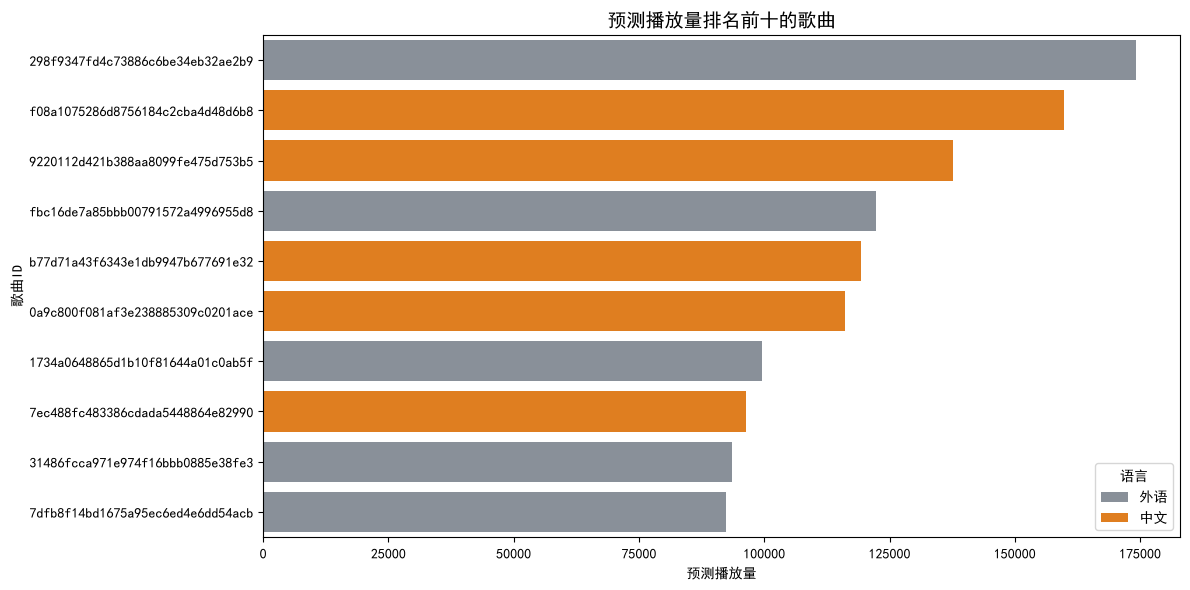

In [60]:
# 6. 预测播放量排名前十的歌曲
def visualize_top_songs(selected_artists):
    song_data = []
    for artist in selected_artists:
        for song in artist['recommended_songs']:
            song_data.append({
                '歌曲ID': song['song_id'],
                '语言': song['language'],
                '预测播放量': song['predicted_plays']
            })
    song_df = pd.DataFrame(song_data)
    
    top_songs = song_df.sort_values('预测播放量', ascending=False).head(10)
    
    plt.figure(figsize=(12, 6))
    sns.barplot(x='预测播放量', y='歌曲ID', hue='语言', data=top_songs, dodge=False,
                palette={'中文': '#FF7D00', '外语': '#86909C'})
    plt.title('预测播放量排名前十的歌曲', fontsize=14)
    plt.xlabel('预测播放量')
    plt.ylabel('歌曲ID')
    plt.legend(title='语言', loc='lower right')
    plt.tight_layout()
    plt.show()
visualize_top_songs(selected_artists)

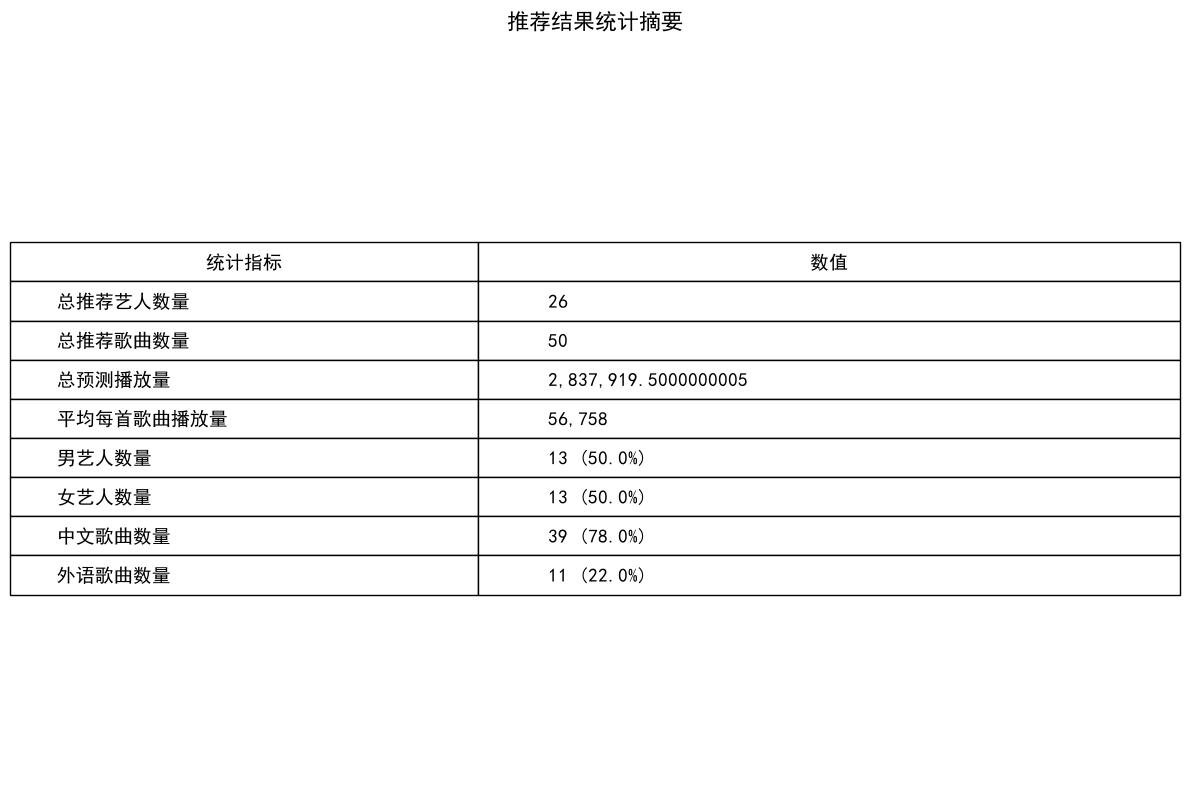

In [61]:
# 7. 艺人与歌曲统计信息表
def visualize_statistics_summary(selected_artists):
    artist_df = pd.DataFrame([
        {
            '艺人ID': artist['artist_id'],
            '性别': artist['gender'],
            '推荐歌曲数': len(artist['recommended_songs']),
            '总预测播放量': artist['total_predicted']
        }
        for artist in selected_artists
    ])
    
    song_data = []
    for artist in selected_artists:
        for song in artist['recommended_songs']:
            song_data.append({
                '性别': artist['gender'],
                '语言': song['language'],
                '预测播放量': song['predicted_plays']
            })
    song_df = pd.DataFrame(song_data)
    
    plt.figure(figsize=(12, 8))
    plt.axis('off')
    plt.title('推荐结果统计摘要', fontsize=16, pad=20)
       # 计算统计信息
    total_artists = len(artist_df)
    total_songs = len(song_df)
    total_predicted_plays = song_df['预测播放量'].sum()
    avg_plays_per_song = song_df['预测播放量'].mean()
    male_artists = len(artist_df[artist_df['性别'] == '男'])
    female_artists = len(artist_df[artist_df['性别'] == '女'])
    male_ratio = male_artists / total_artists * 100
    female_ratio = female_artists / total_artists * 100
    chinese_songs = len(song_df[song_df['语言'] == '中文'])
    foreign_songs = len(song_df[song_df['语言'] == '外语'])
    chinese_ratio = chinese_songs / total_songs * 100
    foreign_ratio = foreign_songs / total_songs * 100
        # 创建表格数据
    table_data = [
        ('总推荐艺人数量', total_artists),
        ('总推荐歌曲数量', total_songs),
        ('总预测播放量', f"{total_predicted_plays:,}"),
        ('平均每首歌曲播放量', f"{avg_plays_per_song:,.0f}"),
        ('男艺人数量', f"{male_artists} ({male_ratio:.1f}%)"),
        ('女艺人数量', f"{female_artists} ({female_ratio:.1f}%)"),
        ('中文歌曲数量', f"{chinese_songs} ({chinese_ratio:.1f}%)"),
        ('外语歌曲数量', f"{foreign_songs} ({foreign_ratio:.1f}%)")
    ]
    
    # 创建表格
    table = plt.table(cellText=table_data, loc='center', cellLoc='left',
                     colLabels=['统计指标', '数值'],
                     colWidths=[0.4, 0.6],
                     fontsize=12)
    table.set_fontsize(14)
    table.scale(1, 2)
    
    plt.tight_layout()
    plt.show()
visualize_statistics_summary(selected_artists)

In [62]:
selected_artists

[{'artist_id': '03c6699ea836decbc5c8fc2dbae7bd3b',
  'gender': '男',
  'recommended_songs': [{'song_id': 'b6c00dc7ba77f1f789f53b7df09c3bdf',
    'language': '中文',
    'predicted_plays': np.float64(17732.42)}],
  'total_predicted': np.float64(17732.42)},
 {'artist_id': '099cd99056bf92e5f0e384465890a804',
  'gender': '女',
  'recommended_songs': [{'song_id': '6a6544eb3eacc20a5c0cd4da5e4e4c7f',
    'language': '外语',
    'predicted_plays': np.float64(58904.79)},
   {'song_id': '4dcd9ea77e2d19657a2cfd9fd0ba113a',
    'language': '外语',
    'predicted_plays': np.float64(48535.68)}],
  'total_predicted': np.float64(107440.47)},
 {'artist_id': '14c4faf6682ac1bb86d346d9a2a1f8e3',
  'gender': '女',
  'recommended_songs': [{'song_id': '33857e8523bd428f57b64b3501bcd027',
    'language': '中文',
    'predicted_plays': np.float64(32714.77)},
   {'song_id': '5a5c6f9101985f3612f3a4e7aea3faf7',
    'language': '中文',
    'predicted_plays': np.float64(17141.25)},
   {'song_id': 'c676f2aa6638d8554d3151d89d5059e

In [63]:
import csv

# 定义CSV表头
headers = ['artist_id', 'gender', 'total_predicted', 'song_id', 'language', 'predicted_plays']

# 准备行数据（展开嵌套的推荐歌曲）
rows = []
for artist in selected_artists:
    artist_id = artist['artist_id']
    gender = artist['gender']
    total_predicted = artist['total_predicted']
    for song in artist['recommended_songs']:
        rows.append({
            'artist_id': artist_id,
            'gender': gender,
            'total_predicted': total_predicted,
            'song_id': song['song_id'],
            'language': song['language'],
            'predicted_plays': song['predicted_plays']
        })

# 写入CSV文件
with open('suggest_artists.csv', 'w', newline='', encoding='utf-8') as csvfile:
    writer = csv.DictWriter(csvfile, fieldnames=headers)
    writer.writeheader()
    writer.writerows(rows)

print("CSV文件已成功保存为suggest_artists.csv")

CSV文件已成功保存为suggest_artists.csv
